# Question 1

In [7]:
import subprocess 
import cymetric as cym 
from cymetric import graphs as cgr
from cymetric import timeseries
import matplotlib.pyplot as plt

subprocess.run(["cyclus", "./open_fuel_cycle.xml"])


              :                                                               
          .CL:CC CC             _Q     _Q  _Q_Q    _Q    _Q              _Q   
        CC;CCCCCCCC:C;         /_\)   /_\)/_/\\)  /_\)  /_\)            /_\)  
        CCCCCCCCCCCCCl       __O|/O___O|/O_OO|/O__O|/O__O|/O____________O|/O__
     CCCCCCf     iCCCLCC     /////////////////////////////////////////////////
     iCCCt  ;;;;;.  CCCC                                                      
    CCCC  ;;;;;;;;;. CClL.                          c                         
   CCCC ,;;       ;;: CCCC  ;                   : CCCCi                       
    CCC ;;         ;;  CC   ;;:                CCC`   `C;                     
  lCCC ;;              CCCC  ;;;:             :CC .;;. C;   ;    :   ;  :;;   
  CCCC ;.              CCCC    ;;;,           CC ;    ; Ci  ;    :   ;  :  ;  
   iCC :;               CC       ;;;,        ;C ;       CC  ;    :   ; .      
  CCCi ;;               CCC        ;;;.      .C ;   

Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental



Status: Cyclus run successful!
Output location: cyclus.sqlite
Simulation ID: 04d908af-123d-4757-bb23-6cff5d64136e


CompletedProcess(args=['cyclus', './open_fuel_cycle.xml'], returncode=0)

/root/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


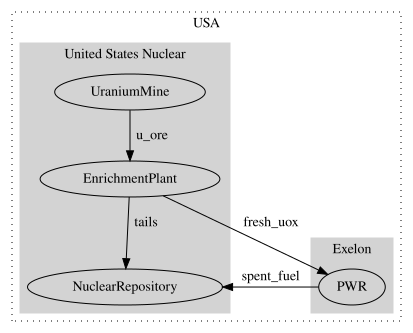

In [1]:
import cymetric as cym 
from cymetric import graphs as cgr
from cymetric import timeseries
import matplotlib.pyplot as plt

cdb = cym.dbopen("cyclus.sqlite")
ev = cym.Evaluator(db=cdb,write=False)

cgr.flow_graph(ev, label='comm')

**Part a)**

<Axes: title={'center': 'Natural Uranium Supplied in Open Fuel Cycle'}, xlabel='Time'>

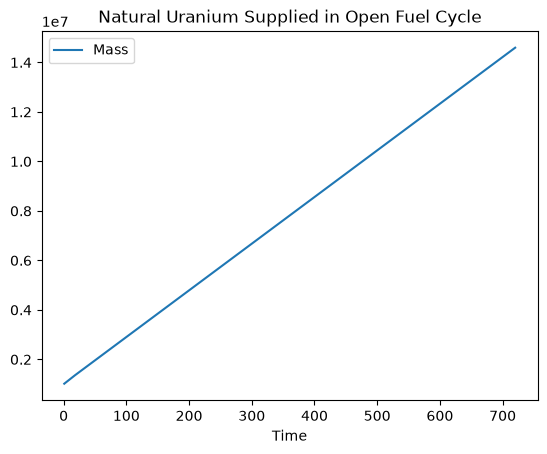

In [ ]:
u=cym.filters.transactions_nuc(ev,commodities=["u_ore"])

u = u.groupby("Time")[["Mass"]].sum()
u.to_csv("mined_u.csv")
u=u.cumsum()
u.plot(y="Mass", title ='Natural Uranium Supplied in Open Fuel Cycle')


**Part b)**

Total Natural Uranium Supplied in the Open Fuel Cycle: 14594.89 MTU
Total Natural Uranium Supplied in the Example: 12558.39 MTU


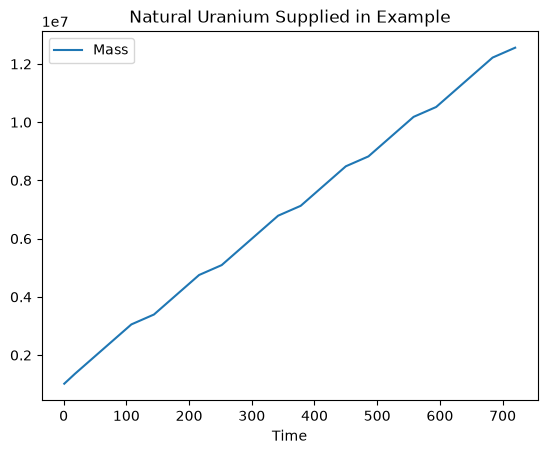

In [3]:
# Amount of natural uranium supplied in the open fuel cycle here is ~2000 MTU greater than
#       that which is shown in the example... reprocessing contributes appreciably to the amount
#       of heavy metal in each feed batch, thereby reducing the required amount of mined uranium for each reload
print(f"Total Natural Uranium Supplied in the Open Fuel Cycle: {round(u.iloc[-1, u.columns.get_loc('Mass')]/1000,2)} MTU")

exdb = cym.dbopen("/workspaces/Workshop-Codespace/examples/cyclus.sqlite")
exev = cym.Evaluator(db=exdb,write=False)
xu=cym.filters.transactions_nuc(exev,commodities=["u_ore"])
xu = xu.groupby("Time")[["Mass"]].sum()
xu=xu.cumsum()
xu.plot(y="Mass", title='Natural Uranium Supplied in Example')
print(f"Total Natural Uranium Supplied in the Example: {round(xu.iloc[-1, xu.columns.get_loc('Mass')]/1000,2)} MTU")

**Part c)**

In [4]:
# Initial Loading + (1 batch/cycle) * (720 months) / (18 months/cycle)
tot_batches = 3 + (720/18)

# in 1kg:
# M_nat_u235 = (0.0495 - 0.003)*M_U_tot
# M_LEU_u235 = (0.00711 - 0.003)*M_U_tot
# 
# M_nat/M_LEU = (0.0495 - 0.003)/(0.00711 - 0.003)
# ==> M_nat = M_LEU*(0.0495 - 0.003)/(0.00711 - 0.003)
# where M_LEU = tot_batches * (30000 kgU/batch)

# Consistent with Cyclus value!
m_nat = tot_batches*(30000)*((4.95 - 0.3)/(0.711 - 0.3))
print(f"Cyclus Calculation of Total Natural Uranium Supplied: {round(u.iloc[-1, u.columns.get_loc('Mass')]/1000,2)} MTU")
print(f"Hand Calculation of Total Natural Uranium Supplied:   {round(m_nat/1000,2)} MTU")

Cyclus Calculation of Total Natural Uranium Supplied: 14594.89 MTU
Hand Calculation of Total Natural Uranium Supplied:   14594.89 MTU


**Part d)**

In [ ]:
# Assuming no unexpected outages in a given cycle (17mo @ HFP, 1mo S/D):
# BU = (1148 MWe)*(1/0.33 MWth/MWe) * (3 cycles)*(17 months/cycle)*(31 days/month) / (90 MTU)

# This value is somewhat consistent w/ average region discharge burnup, though batch-wise BU values
#       tend to hover around 40-55 GWD/MTU IRL, affected by assembly power and individual loadings
# Most 18mo cycle PWR fuels tend to be licensed to a peak pin burnup of ~60-65 GWD/MTU, so it isn't unrealistic, either
bu = 1148*(1/0.33)*(3*17*31)/90
print(f"Batch-wise Average Discharge Burnup: {round(bu,2)} MWD/MTU")

Batch-wise Average Discharge Burnup: 61110.71 MWD/MTU


**Part e)**

In [17]:
# Nat. U Utilization = (M_nat,tot) / ((1148 MWe) * (Years of Operation))
# Years of Operation = (720 months)/(12 months/yr) - Total Reload Time
# Total Reload Years = ((1 reload/cycle)* (720 months)/(18 months/cycle)) / (12 months/yr)
nat_u_util = m_nat / (1148*((720/12)-((720/18)/12)))

# Value consistent with PWR values (~200-250 MTU/EFPY)
print(f"Natural Uranium Utilization per EFPY: {round(nat_u_util,2)} MTU/EFPY")

Natural Uranium Utilization per EFPY: 224.35 MTU/EFPY


**Part f)**

In [10]:
# Using 2 batches per cycle saves about ~140 MTU of natural uranium, though it's more practical to keep it at
#       3 batches per cycle for the fuel management when it comes to keeping margins for limits relevant to kW/ft
#       and power density. It is also more practical to maintain a three-batch fuel management scheme, rather than two;
#       the latter means much more feed and discharge assemblies, greatly inceasing costs.
tot_batches_f = 2 + (720/18)
m_nat_f = tot_batches_f*(30000)*((4.95 - 0.3)/(0.711 - 0.3))
print(f"Total Natural Uranium Supplied for 2 Batch Fuel Management: {round(m_nat_f/1000,2)} MTU")
# Original:
print(f"Total Natural Uranium Supplied for 3 Batch Fuel Management: {round(m_nat/1000,2)} MTU")

Total Natural Uranium Supplied for 2 Batch Fuel Management: 14255.47 MTU
Total Natural Uranium Supplied for 3 Batch Fuel Management: 14594.89 MTU
